# BookShelf: Goodbooks-10k + расширенные описания

Отдельный эксперимент после исследования Amazon. Цель — проверить content, item-based adjusted cosine и их гибрид на полной истории читателей и метаданных с небольшим числом пропусков.

Источники: [полные оценки Goodbooks-10k](https://github.com/zygmuntz/goodbooks-10k), [расширение метаданных](https://github.com/malcolmosh/goodbooks-10k-extended). Лицензии и SHA-256 скачанных файлов находятся в `data/GoodBooksFull/`. Команда загрузки из корня: `python -m ml.download_goodbooks`. Исходный `data/GoodBooks/` сохранён.

Зависимости уже описаны в проекте: `python -m pip install -e ".[dev,recommendations]"`. Используется то же ядро `src/recsys/engine.py`, что и в gRPC-сервисе. Датасет не импортируется в production-БД.

После изменения интерфейса рекомендателя код использует `HybridRecommender(encoder)`, явную подготовку каталога через `prepare()` и ранжирование через `rank()`. Сохранённые результаты относятся к предыдущему полному прогону; весь эксперимент после рефакторинга повторно не запускался.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
import sys
import gc
import json
import logging
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ml.goodbooks import load_goodbooks, split_by_user, iter_ratings
from ml.goodbooks_eval import evaluate_suite, paired_difference
from recsys.engine import HybridRecommender
from recsys.domain import UserProfile
from recsys.embeddings import FastEmbedEncoder, DEFAULT_MODEL

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s")
SEED = 42
EVAL_USERS = int(os.environ.get("GOODBOOKS_EVAL_USERS", "1000"))
assert EVAL_USERS > 0
DATA = ROOT / "data/GoodBooksFull"
ARTIFACTS = ROOT / "notebooks/artifacts/goodbooks"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print({"seed": SEED, "eval_users": EVAL_USERS, "model": DEFAULT_MODEL})

{'seed': 42, 'eval_users': 1000, 'model': 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'}


## Данные и идентификаторы

Используем все оценки и все 10 000 книг, без отбора популярных кандидатов и обрезки пользовательской истории. `ratings.book_id` ссылается на внутренний `books.book_id` актуальной версии. Расширение присоединяется по `goodreads_book_id` с проверкой один-к-одному; названия для склейки не используются.

Оценки 1–5 переводятся в 2–10. `average_rating`, `ratings_count`, распределения оценок и `similar_books` из метаданных не используются для обучения или ранжирования: популярность считается только по обучающим взаимодействиям. Векторы строятся по названию, описанию и жанрам. Жанры и описания расширения собраны позже исходных оценок; это статический benchmark, а не историческая реконструкция.

In [2]:
books, ratings, data_summary = load_goodbooks(DATA)
assert len(books) == 10000
assert len(ratings) == 5976479, "Expected the full canonical Goodbooks ratings file"
display(pd.Series(data_summary, name="Full Goodbooks"))
source_manifest = json.loads((DATA / "sources.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{"file": name, "bytes": entry["bytes"], "sha256": entry["sha256"]}
                      for name, entry in source_manifest["files"].items()]))

ratings               5.976479e+06
users                 5.342400e+04
books                 1.000000e+04
history_min           1.900000e+01
history_median        1.110000e+02
history_mean          1.118688e+02
empty_descriptions    5.700000e+01
empty_genres          0.000000e+00
Name: Full Goodbooks, dtype: float64

,file,bytes,sha256
0,ratings.csv,72126826,1ee8a97172bd6d97147a30d9cfb3029ac240bd27ba2aa9...
1,books.csv,3286659,4d21d0e0433128657c752e3a3d0405ac0ec11675d6c70c...
2,books_enriched.csv,13598730,13a938aa6cd7be91bc04173fea75506a490549e340f554...
3,LICENSE.goodbooks.txt,187,1a459ea0f6e7f28d4eba7df0ddace58e0874e53dad4f78...
4,LICENSE.extended.txt,187,1a459ea0f6e7f28d4eba7df0ddace58e0874e53dad4f78...


## Разбиение 80/10/10 внутри каждого пользователя

В CSV отсутствуют точные timestamps. Поэтому используем воспроизводимое случайное разбиение внутри пользователя, seed=42, а не называем его временным. Каждый читатель сохраняет train-историю; непересекающиеся validation и test содержат остальные оценки. Это проверка рекомендаций для известных читателей. Холодный старт показываем отдельно как пример, он не включён в итоговую таблицу warm-start.

Каталог кандидатов — все 10 000 книг за исключением известных читателю. Положительная релевантность — оценка ≥8. Пользователи без положительной оценки в соответствующем holdout не участвуют в ranking-метриках, их число видно как разница между всеми пользователями и `eligible_users`. Одни и те же детерминированно выбранные 1 000 пользователей оцениваются всеми вариантами внутри каждого периода. Значения метрик этого протокола нельзя напрямую сравнивать с глобальным временным split на Amazon.

In [3]:
train, validation, test = split_by_user(ratings, seed=SEED)
assert len(train) + len(validation) + len(test) == len(ratings)
assert set(train.user_id) == set(validation.user_id) == set(test.user_id)
assert sum(len(part) for part in (train, validation, test)) == len(ratings)
split_summary = pd.DataFrame([
    {"split": name, "ratings": len(part), "users": part.user_id.nunique(),
     "books": part.book_id.nunique(), "positive_ratings": int(part.score.ge(8).sum())}
    for name, part in [("train", train), ("validation", validation), ("test", test)]
])
display(split_summary)
del ratings
gc.collect()

,split,ratings,users,books,positive_ratings
0,train,4759759,53424,10000,3282179
1,validation,573580,53424,9999,395746
2,test,643140,53424,9999,444186


220

## Ядро: сохранение силы CF и корректные baseline

Content — cosine с профилем высоко оценённых книг; мультиязычные эмбеддинги FastEmbed/ONNX, без дообучения. Adjusted cosine использует только общих читателей в числителе и знаменателе, центрирование по среднему читателя, минимум 2 общих читателя и 3 оценки кандидата, shrinkage `n_common/(n_common+10)`.

CF-балл исправлен: `clip(sum(sim * preference) / max(1, sum(abs(preference))), 0, 1)`, где `preference=(rating-5.5)/4.5`. Нормировщик зависит от профиля, а не от сходства кандидата. При единственной оценённой книге слабое сходство больше не сокращается в дроби и не превращается в сильное.

Baseline `popularity` ранжирует по числу train-оценок; `bayesian` отдельно ранжирует по сглаженной средней train-оценке. Случайный baseline исключает уже известные книги. Это позволяет проверить, насколько рекомендации полезнее простого популярного топа.

Для массовой offline-оценки точные сходства вычисляются блоками и хранятся в `.cache/cf/goodbooks/` через memory mapping: около 400 MB на один снимок. Полная матрица не собирается одновременно в RAM. При изменении оценок кэш меняется по хэшу. gRPC по умолчанию считает те же сходства по мере необходимости.

Гибрид дополнительно калибрует оба сигнала по percentile-рангам среди допустимых кандидатов (одинаковые баллы получают одинаковый ранг; нулевой сигнал остаётся нулевым). Это устраняет несопоставимость диапазонов cosine и исправленного CF при смешивании. Для контролируемого сравнения оставляем вариант `hybrid_raw` без калибровки. Pure content и CF сохраняют исходные баллы и свой порядок. Калибровка выбрана после анализа validation; test для выбора формулы или веса не используется.

In [4]:
encoder = FastEmbedEncoder(cache_dir=str(ROOT / ".cache/models"))
started = time.perf_counter()
model = HybridRecommender(encoder)
train_catalog = model.prepare(books, iter_ratings(train))
print("Training profiles and sparse matrix ready:", train_catalog.centered.shape, "nnz=", train_catalog.centered.nnz,
      "seconds=", round(time.perf_counter() - started, 1), flush=True)
train_catalog.precompute_similarities(str(ROOT / ".cache/cf/goodbooks"))
print("Exact CF similarities ready", flush=True)

Training profiles and sparse matrix ready: (10000, 53424) nnz= 4759759 seconds= 22.1


Exact CF similarities ready


## Validation: подбор только веса смешивания

Сравниваем random, popularity, bayesian, content и CF. Для гибрида перебираем `cf_weight` от 0 до 1; 0 разрешает чистый content. Формула смешивания из README сохраняется: `w=cf_weight*n_ratings/(n_ratings+10)`, без CF-свидетельств `w=0`.

Выбираем вес по NDCG@10 только на validation. Все варианты ранжируют весь каталог оставшихся книг без sampled negatives. Recall@10 и NDCG@10 усредняются по пользователям; HitRate@10 показывает долю читателей хотя бы с одним попаданием; coverage — долю уникальных книг в выдачах этой выборки. Интервалы — 95% percentile bootstrap по пользователям, 500 повторов, seed=42.

Одну и ту же сетку весов проверяем и для калиброванного гибрида, и для `hybrid_raw`. Лучший вес каждого варианта выбирается отдельно только по validation. В тестовой таблице показываем оба.

In [5]:
weights = [0, 0.25, 0.5, 0.75, 0.9, 0.95, 1]
configurations = {"random": ("random", None), "popularity": ("popularity", None),
                  "bayesian": ("bayesian", None), "content": ("content", None), "cf": ("cf", None)}
configurations.update({f"hybrid_{weight:g}": ("hybrid", weight) for weight in weights})
configurations.update({f"raw_{weight:g}": ("hybrid_raw", weight) for weight in weights})
validation_results, validation_details = evaluate_suite(model, train_catalog, validation, configurations,
                                                        max_users=EVAL_USERS, seed=SEED)
display(validation_results)
hybrid_rows = validation_results[validation_results.model.str.startswith("hybrid_")]
best_label = hybrid_rows.sort_values("ndcg@10", ascending=False, kind="stable").iloc[0].model
best_weight = configurations[best_label][1]
raw_rows = validation_results[validation_results.model.str.startswith("raw_")]
best_raw_label = raw_rows.sort_values("ndcg@10", ascending=False, kind="stable").iloc[0].model
best_raw_weight = configurations[best_raw_label][1]
print("Selected raw weight:", best_raw_weight)
print("Selected on validation:", best_label)
print("Best validation baseline or hybrid:", validation_results.sort_values("ndcg@10", ascending=False).iloc[0].model)
validation_results.to_csv(ARTIFACTS / "validation.csv", index=False)
validation_details.to_csv(ARTIFACTS / "validation_users.csv", index=False)

2026-11-17 22:12:35,027 Evaluation: 100/1000 users


2026-11-17 22:12:57,120 Evaluation: 200/1000 users


2026-11-17 22:13:20,744 Evaluation: 300/1000 users


2026-11-17 22:13:56,092 Evaluation: 400/1000 users


2026-11-17 22:14:26,182 Evaluation: 500/1000 users


2026-11-17 22:14:49,074 Evaluation: 600/1000 users


... (2 outputs left out)

2026-11-17 22:15:57,624 Evaluation: 900/1000 users


2026-11-17 22:16:20,360 Evaluation: 1000/1000 users


,model,users,eligible_users,cold_users,coverage@10,recall@10,recall@10_low,recall@10_high,ndcg@10,ndcg@10_low,ndcg@10_high,hit_rate@10,hit_rate@10_low,hit_rate@10_high
0,random,1000,53162,0,0.6342,0.000454,0.000071,0.000853,0.000396,0.000085,0.000731,0.005,0.001000,0.009000
1,popularity,1000,53162,0,0.0031,0.048501,0.042801,0.054914,0.048370,0.042613,0.054524,0.280,0.253000,0.307000
2,bayesian,1000,53162,0,0.0013,0.000732,0.000243,0.001446,0.000665,0.000202,0.001351,0.006,0.002000,0.012000
3,content,1000,53162,0,0.0647,0.009714,0.007235,0.013044,0.008848,0.006529,0.011564,0.060,0.047000,0.075000
4,cf,1000,53162,0,0.2058,0.066263,0.059008,0.073541,0.064298,0.057313,0.070866,0.338,0.308475,0.368000
5,hybrid_0,1000,53162,0,0.0647,0.009714,0.007235,0.013044,0.008848,0.006529,0.011564,0.060,0.047000,0.075000
6,hybrid_0.25,1000,53162,0,0.1336,0.028954,0.024544,0.033720,0.029264,0.024764,0.033790,0.179,0.156475,0.203000
7,hybrid_0.5,1000,53162,0,0.1501,0.037257,0.032418,0.042338,0.036858,0.031619,0.041654,0.219,0.194475,0.244000
8,hybrid_0.75,1000,53162,0,0.1652,0.044953,0.039381,0.049994,0.044114,0.038266,0.049317,0.263,0.232950,0.288000
9,hybrid_0.9,1000,53162,0,0.1794,0.055674,0.049594,0.061240,0.054044,0.047823,0.060032,0.307,0.276475,0.333050


Selected raw weight: 0.5
Selected on validation: hybrid_1
Best validation baseline or hybrid: hybrid_1


## Test: фиксируем выбранный вес

Перед test добавляем validation в историю, сохраняя все книги и оценки. Вес, пороги и shrinkage после просмотра test не меняются. Освобождаем train-модель до повторного построения, чтобы не держать две большие модели в памяти. Результаты относятся к сочетанию новых данных, протокола и исправленного алгоритма; отдельно приписать весь эффект смене датасета нельзя.

In [6]:
train_catalog = None
gc.collect()
fit_data = pd.concat([train, validation], ignore_index=True)
model.cf_weight = best_weight
test_catalog = model.prepare(books, iter_ratings(fit_data))
test_catalog.precompute_similarities(str(ROOT / ".cache/cf/goodbooks"))
print("Train+validation history:", len(fit_data), "ratings", flush=True)
test_configurations = {"random": ("random", None), "popularity": ("popularity", None),
                       "bayesian": ("bayesian", None), "content": ("content", None),
                       "cf": ("cf", None), "hybrid_raw": ("hybrid_raw", best_raw_weight),
                       "hybrid": ("hybrid", best_weight)}
test_results, test_details = evaluate_suite(model, test_catalog, test, test_configurations,
                                           max_users=EVAL_USERS, seed=SEED)
display(test_results)
display(pd.DataFrame([paired_difference(test_details, "hybrid", name) for name in ["content", "popularity", "cf", "hybrid_raw"]]))
test_results.to_csv(ARTIFACTS / "test.csv", index=False)
test_details.to_csv(ARTIFACTS / "test_users.csv", index=False)
parameters = {"seed": SEED, "eval_users": EVAL_USERS, "cf_weight": best_weight, "raw_cf_weight": best_raw_weight, "fusion": "candidate percentile ranks",
              "protocol": "per-user random 80/10/10; full catalog", "embedding_model": DEFAULT_MODEL,
              "data": data_summary, "sources": source_manifest}
(ARTIFACTS / "experiment.json").write_text(json.dumps(parameters, indent=2, ensure_ascii=False), encoding="utf-8")

Train+validation history: 5333339 ratings


2026-11-17 22:16:52,283 Evaluation: 100/1000 users


2026-11-17 22:16:59,745 Evaluation: 200/1000 users


2026-11-17 22:17:06,930 Evaluation: 300/1000 users


2026-11-17 22:17:14,263 Evaluation: 400/1000 users


2026-11-17 22:17:22,035 Evaluation: 500/1000 users


... (4 outputs left out)

2026-11-17 22:18:00,265 Evaluation: 1000/1000 users


,model,users,eligible_users,cold_users,coverage@10,recall@10,recall@10_low,recall@10_high,ndcg@10,ndcg@10_low,ndcg@10_high,hit_rate@10,hit_rate@10_low,hit_rate@10_high
0,random,1000,53260,0,0.6316,0.000700,0.000226,0.001321,0.000620,0.000177,0.001200,0.007,0.002000,0.013000
1,popularity,1000,53260,0,0.0038,0.050198,0.044919,0.056064,0.054246,0.049047,0.060294,0.301,0.276475,0.329525
2,bayesian,1000,53260,0,0.0015,0.000877,0.000200,0.001733,0.000996,0.000222,0.002019,0.006,0.002000,0.011000
3,content,1000,53260,0,0.0602,0.011312,0.008170,0.015133,0.010413,0.007519,0.013480,0.067,0.053000,0.083000
4,cf,1000,53260,0,0.2047,0.069860,0.062779,0.077150,0.074831,0.066943,0.083048,0.371,0.341000,0.401525
5,hybrid_raw,1000,53260,0,0.1260,0.017519,0.013826,0.021664,0.016600,0.012847,0.020860,0.109,0.091475,0.129000
6,hybrid,1000,53260,0,0.1608,0.085966,0.077042,0.094766,0.097118,0.087849,0.106201,0.430,0.398000,0.461525


,comparison,metric,delta,low,high
0,hybrid - content,ndcg@10,0.086706,0.077991,0.096012
1,hybrid - popularity,ndcg@10,0.042872,0.033840,0.052924
2,hybrid - cf,ndcg@10,0.022287,0.015950,0.028314
3,hybrid - hybrid_raw,ndcg@10,0.080518,0.072510,0.088751


2054

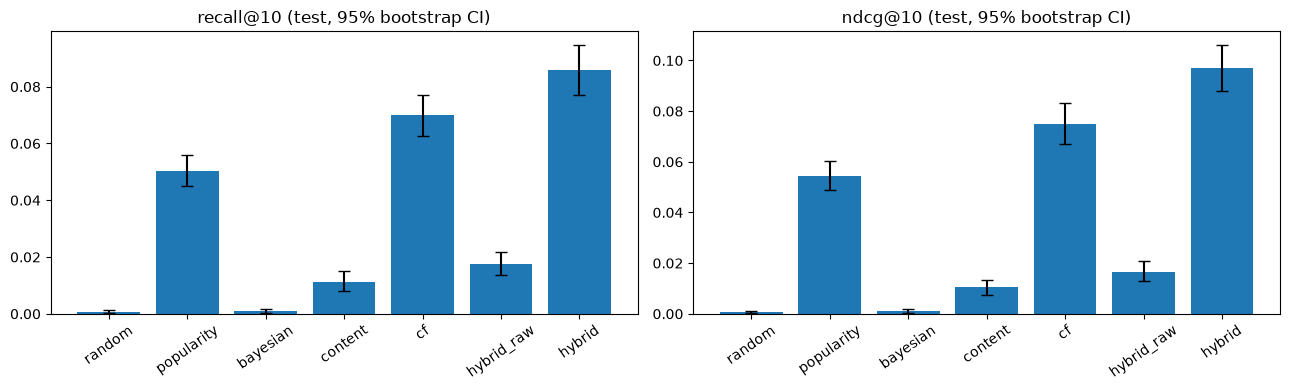

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["recall@10", "ndcg@10"]):
    values = test_results[metric].to_numpy()
    errors = np.array([values - test_results[metric + "_low"], test_results[metric + "_high"] - values])
    ax.bar(test_results.model, values, yerr=np.maximum(errors, 0), capsize=4)
    ax.set_title(metric + " (test, 95% bootstrap CI)")
    ax.tick_params(axis="x", rotation=35)
    ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(ARTIFACTS / "test_comparison.png", dpi=160)
plt.show()

## Примеры для читателя с историей и холодный старт

In [8]:
uid = int(test_details.user_id.iloc[0])
history = test_catalog.user_ratings[uid]
display(pd.DataFrame([{"title": books[test_catalog.index[bid]].title, "rating": score}
                      for bid, score in history.items() if score >= 8]).head(12))
print("Personalized recommendations:")
display(pd.DataFrame([vars(item) for item in model.rank(test_catalog, UserProfile(uid))]))
print("New reader with interests:")
display(pd.DataFrame([vars(item) for item in model.rank(test_catalog, UserProfile(-1, interests=("fantasy", "science fiction")))]))
assert not set(history) & {item.book_id for item in model.rank(test_catalog, UserProfile(uid))}

,title,rating
0,"Leviathan Wakes (The Expanse, #1)",8
1,The Son,8
2,"Lords of the North (The Saxon Stories, #3)",8
3,Alexander Hamilton,8
4,Slade House,8
5,"Empire of the Sun (Empire of the Sun, #1)",8
6,Freedom,8
7,The Bone Clocks,8
8,A Tale of Two Cities,10
9,"Gödel, Escher, Bach: An Eternal Golden Braid",8


Personalized recommendations:


,book_id,title,score
0,25,Harry Potter and the Deathly Hallows (Harry Po...,0.999521
1,103,The Count of Monte Cristo,0.999407
2,27,Harry Potter and the Half-Blood Prince (Harry ...,0.999383
3,161,"The Return of the King (The Lord of the Rings,...",0.999277
4,143,All the Light We Cannot See,0.999223
5,1552,"The Killer Angels (The Civil War Trilogy, #2)",0.999026
6,209,"The Silence of the Lambs (Hannibal Lecter, #2)",0.998974
7,39,"A Game of Thrones (A Song of Ice and Fire, #1)",0.998893
8,4,To Kill a Mockingbird,0.998726
9,110,"A Clash of Kings (A Song of Ice and Fire, #2)",0.998702


New reader with interests:


,book_id,title,score
0,7921,2BR02B,1.0000
1,6514,The Hat,0.9999
2,1120,Aesop's Fables,0.9998
3,7573,Among Others,0.9997
4,6273,In Our Time,0.9996
5,1029,"Saga, Vol. 1 (Saga, #1)",0.9995
6,7640,Stone Mattress: Nine Tales,0.9994
7,4583,Micro,0.9993
8,9829,طه الغريب,0.9992
9,6431,"Path of Destruction (Star Wars: Darth Bane, #1)",0.9991


## Интерпретация

Сначала сравнивайте персональные алгоритмы с popularity и random в этой же таблице. Больший размер данных сам по себе не гарантирует улучшения. Если гибрид уступает CF или content, это нужно сохранить в выводах, а не подбирать вес по test. Парные bootstrap-интервалы учитывают, что варианты оценивались на одних читателях; интервал разницы, содержащий ноль, не подтверждает уверенное превосходство на этой выборке.

Проверка выполнена для пользователей с историей. Переход к случайному разбиению повышает доступность истории по сравнению с глобальным временным split и меняет задачу. Результаты Amazon остаются отдельным историческим экспериментом. Холодный старт и поддержку русского языка нужно оценивать отдельно; этот benchmark их не доказывает.

Новые данные не заменяют каталог BookShelf: API и gRPC получают реальные книги и оценки приложения. Исправление CF и baseline используется общим ядром; экспериментальный вес из Goodbooks не перезаписывает настройки рабочего сервиса автоматически.

**Сохранённый итоговый прогон:** validation выбрала `cf_weight=1` для гибрида и `0.5` для raw-варианта. На 1 000 test-пользователях из 53 260 доступных гибрид получил Recall@10=0.0860, NDCG@10=0.0971, HitRate@10=0.430; CF — 0.0699, 0.0748, 0.371; популярность — 0.0502, 0.0542, 0.301. Покрытие гибрида 0.1608 ниже покрытия CF 0.2047.

Парная разница NDCG `hybrid - cf`: 0.0223, 95% bootstrap CI [0.0160; 0.0283]. В этой выборке преимущество гибрида поддерживается интервалом, однако один split не проверяет устойчивость по другим seed и перенос на новых пользователей. Слабый content (NDCG=0.0104) показывает, что полнота описаний не гарантирует качество усреднённого профиля. Raw-гибрид (NDCG=0.0166) подтверждает необходимость сопоставимых шкал при смешивании.